In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../'))
sys.path.append(base_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from tqdm import tqdm
import pandas as pd
from IPython.display import display
from sklearn.mixture import GaussianMixture


import project_images_loader as pil
import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import utils.util_freesurfer_segmentation as util_freesurfer
from PIL import Image
import random
import time

import skitlearn_segmentation as sks

np.set_printoptions(precision=4)
import tensorflow as tf

%matplotlib widget


SERVER: False


# Load images

In [2]:
def load_img_and_mask(id, hunt, no_cerebellum=False):
    # img_path_name = pil.get_registered_to_template_image_path_name(hunt, id, pil.REGISTRATION_TO_MNI, absolute=True)
    img_path_name = pil.get_preprocessed_image_path_name(hunt, id, absolute=True)
    mask_path_name = pil.get_brain_mask_path_name(hunt, id, pil.REGISTRATION_TO_MNI, no_cerebellum=no_cerebellum, absolute=True)

    img, _ = nfc.load_nifti(img_path_name)
    mask, _ = nfc.load_nifti(mask_path_name)
    if no_cerebellum:
        img *= mask
    return img, mask

def load_img_mask_and_segmentation(id, hunt, no_cerebellum=False):
    img, mask = load_img_and_mask(id, hunt, no_cerebellum=no_cerebellum)
    seg_path_name = pil.get_segmentation_path_name(hunt, id, 3, absolute=True)
    seg, _ = nfc.load_nifti(seg_path_name)
    if no_cerebellum:
        seg *= mask
    return img, mask, seg

matching_ids = pil.get_matching_ids()


# Fake EM using precomputed Gaussian Mixture Model

In [3]:
def change_labels(segmentation, means):
    indices = np.argsort(means)
    _seg_channels = np.ones((*segmentation.shape, means.shape[0]+1), dtype=np.uint8)
    for i in range(means.shape[0]):
        _seg_channels[:,:,:,i+1] = np.where(segmentation == indices[i]+1, 2, 0)
    return np.argmax(_seg_channels, axis=3)

def recover_image(flat_img, mask):
    flat_mask = mask.ravel()
    result = np.zeros_like(flat_mask, dtype=flat_img.dtype)
    result[flat_mask > 0] = flat_img
    return result.reshape(*mask.shape)

def recover_labels(flat_img, mask):
    return recover_image(flat_img, mask) + 1 * mask

def order_probs_tf(elem_list, means):
    indices = tf.argsort(means)
    return [tf.gather(elem, indices, axis=0).numpy() for elem in elem_list]

def em_sklearn(data, k, min_change=0.005, max_iterations=50):       
    gmm = GaussianMixture(n_components=k, max_iter=max_iterations, tol=min_change)
    labels = gmm.fit_predict(data[:,np.newaxis])
    probs = gmm.predict_proba(data[:, np.newaxis])

    return labels, np.squeeze(gmm.means_), np.squeeze(gmm.covariances_), np.squeeze(gmm.weights_), probs

def _prob_x_given_k(data, means, stds):
    scale_factor = 1 / (stds * np.sqrt(2 * np.pi))
    exponent = -0.5 * ((data[:, np.newaxis] - means) / stds) ** 2
    pdf = scale_factor * np.exp(exponent)
    return pdf

def label_using_gmm(fletten_img, means, stds, weights):
    prob_x_given_k = _prob_x_given_k(fletten_img, means, stds)
    w = prob_x_given_k * weights[np.newaxis, :]
    den = np.sum(w, axis=1)
    probs = w / den[:, np.newaxis]
    return np.argmax(probs, axis=1), probs


def dice_smooth(y_true, y_pred, smooth=1e-6):
    intersection = np.sum(y_true * y_pred, axis=0)
    union = np.sum(y_true, axis=0) + np.sum(y_pred, axis=0)
    dice = (2. * intersection + smooth) / (union + smooth)
    return dice

def labels_flat_to_onehot(labels_flat, n_classes):
    labels_onehot = np.zeros((labels_flat.shape[0], n_classes))
    for i in range(n_classes):
        labels_onehot[labels_flat == i,i] = 1
    return labels_onehot


In [4]:
def measure_em_execution_time():
    img, mask, seg = load_img_mask_and_segmentation(matching_ids[0], 3)
    mask_from_seg = np.where(seg > 0, 1, 0)
    data = img.ravel()[mask_from_seg.ravel() > 0]

    min_change = 0.01
    for i in range(1, 10):
        start_time = time.time()
        _current_min_change = min_change/2**i
        em_sklearn(data, 3, min_change=_current_min_change, max_iterations=50)
        print(f"{i} - {_current_min_change}:{time.time()-start_time}")

    # 1 - 0.005:1.4883556365966797
    # 2 - 0.0025:1.8245010375976562
    # 3 - 0.00125:3.0725622177124023
    # 4 - 0.000625:4.899451732635498
    # 5 - 0.0003125:5.988347768783569

In [5]:
def test_label_using_gmm(id_index=0):
    # load images
    id = matching_ids[id_index]
    img, mask, seg = load_img_mask_and_segmentation(id, 3, no_cerebellum=False)

    mask_from_seg = np.where(seg > 0, 1, 0)
    img_flat_masked = img.ravel()[mask_from_seg.ravel() > 0]
    seg_flat_masked = seg.ravel()[mask_from_seg.ravel() > 0]

    # run EM
    _, means, cov, classs_weights, probs = em_sklearn(img_flat_masked, 3, min_change=0.005, max_iterations=50)
    probs, means, cov, classs_weights = order_probs_tf([probs.T, means, cov, classs_weights],  means)
    probs = probs.T
    labels = np.argmax(probs, axis=1)

    # label using EM
    labels_rec, probs_rec = label_using_gmm(img.ravel()[mask_from_seg.ravel() > 0], means, np.sqrt(cov), classs_weights)

    # compute dice
    labels_onehot = labels_flat_to_onehot(labels, 3)
    labels_rec_onehot = labels_flat_to_onehot(labels_rec, 3)
    seg_flat_masked_one_hot = labels_flat_to_onehot(seg_flat_masked-1, 3)

    dice_sm_base = dice_smooth(labels_onehot, probs, smooth=1e-6)
    dice_sm_labels = dice_smooth(labels_onehot, probs_rec, smooth=1e-6)
    dice_sm_labels_rec = dice_smooth(labels_rec_onehot, probs_rec, smooth=1e-6)
    dice_sm_seg_flat_masked = dice_smooth(seg_flat_masked_one_hot, probs_rec, smooth=1e-6)
    print(f"smoothed dice base: {dice_sm_base}")
    print(f"smoothed dice labels: {dice_sm_labels}")
    print(f"smoothed dice labels_rec: {dice_sm_labels_rec}")
    print(f"smoothed dice sm_seg_flat_masked: {dice_sm_seg_flat_masked}")

    # show images
    probs_csf = recover_image(probs_rec[:,0], mask_from_seg)
    labels_csf = recover_image(seg_flat_masked_one_hot[:,0], mask_from_seg)

    labels = recover_labels(labels, mask_from_seg)
    labels_rec = recover_labels(labels_rec, mask_from_seg)

    # fc.imgshow_3D(f"img {id}", img)
    # fc.imgshow_3D(f"seg {id}", seg)
    # fc.imgshow_3D(f"seg EM {id}", labels)
    # fc.imgshow_3D(f"seg rec EM {id}", labels_rec)
    fc.imgshow_3D(f"probs_csf{id}", probs_csf, range_values=[0,1])
    fc.imgshow_3D(f"probs_csf{id}", labels_csf, range_values=[0,1])

# test_label_using_gmm(id_index=0)

In [6]:
def test_inter_images(id_index1=0, id_index2=1, hunt_1=3, hunt_2=3):
    id1 = matching_ids[id_index1]
    id2 = matching_ids[id_index2]

    img1, mask1, seg1 = load_img_mask_and_segmentation(id1, hunt_1)
    img2, mask2, seg2 = load_img_mask_and_segmentation(id2, hunt_2)

    mask_from_seg1 = np.where(seg1 > 0, 1, 0)
    mask_from_seg2 = np.where(seg2 > 0, 1, 0)

    img_1_flat_masked = img1.ravel()[mask_from_seg1.ravel() > 0]
    img_2_flat_masked = img2.ravel()[mask_from_seg2.ravel() > 0]


    labels1, means1, cov1, classs_weights1 = em_sklearn(img_1_flat_masked, 3, min_change=0.005, max_iterations=50)
    labels2, means2, cov2, classs_weights2 = em_sklearn(img_2_flat_masked, 3, min_change=0.005, max_iterations=50)

    labels1_rec, probs1 = label_using_gmm(img_1_flat_masked, means2, np.sqrt(cov2), classs_weights2)
    labels2_rec, probs2 = label_using_gmm(img_2_flat_masked, means1, np.sqrt(cov1), classs_weights1)

    labels1 = change_labels(recover_labels(labels1, mask_from_seg1), means1)
    labels2 = change_labels(recover_labels(labels2, mask_from_seg2), means2)

    labels1_rec = change_labels(recover_labels(labels1_rec, mask_from_seg1), means2)
    labels2_rec = change_labels(recover_labels(labels2_rec, mask_from_seg2), means1)
    
    print(f"means1: {means1} - means2: {means2}")
    print(f"cov1: {cov1} - cov2: {cov2}")
    print(f"classs_weights1: {classs_weights1} - classs_weights2: {classs_weights2}")


    dices_org_1 = util.compute_multiple_dice_coefficients(labels1, seg1)
    dices_org_2 = util.compute_multiple_dice_coefficients(labels2, seg2)

    dices_1 = util.compute_multiple_dice_coefficients(labels1, labels1_rec)
    dices_2 = util.compute_multiple_dice_coefficients(labels2, labels2_rec)

    print(f"dices_org_1: {dices_org_1}")
    print(f"dices_org_2: {dices_org_2}")

    print(f"dices_1: {dices_1}")
    print(f"dices_2: {dices_2}")

    # fc.imgshow_3D(f"labels1 {id1}", labels1)
    # fc.imgshow_3D(f"labels1_rec {id1}", labels1_rec)

    # fc.imgshow_3D(f"labels2 {id2}", labels2)
    # fc.imgshow_3D(f"labels2_rec {id2}", labels2_rec)

# test_inter_images(id_index1=0, id_index2=0, hunt_1=3, hunt_2=4)

# Fake EM using precomputed Gaussian Mixture Model Tensorflow


In [7]:

# def em_sklearn_tf(data, k, min_change=0.005, max_iterations=50):       
#     gmm = GaussianMixture(n_components=k, max_iter=max_iterations, tol=min_change)
#     labels = gmm.fit_predict(data[:,np.newaxis])
#     probs = gmm.predict_proba(data[:, np.newaxis])
#     return labels.astype(np.float32), np.squeeze(gmm.means_).astype(np.float32), np.squeeze(gmm.covariances_).astype(np.float32), np.squeeze(gmm.weights_).astype(np.float32), probs.astype(np.float32)


# def _prob_x_given_k_tf(data, means, stds):   
#     scale_factor = 1 / (stds * tf.sqrt(2 * tf.constant(np.pi, dtype=tf.float32)))
#     exponent = -0.5 * ((data[:, tf.newaxis] - means) / stds) ** 2
#     pdf = scale_factor * tf.exp(exponent)
#     return pdf

# def label_using_gmm_tf(fletten_img, means, stds, weights):
#     prob_x_given_k = _prob_x_given_k_tf(fletten_img, means, stds)
#     # weights = tf.convert_to_tensor(weights, dtype=tf.float32)
#     w = prob_x_given_k * weights[tf.newaxis, :]
#     den = tf.reduce_sum(w, axis=1)
#     probs = w / den[:, tf.newaxis]
#     labels = tf.argmax(probs, axis=1)
#     return labels, probs

# def order_probs_tf(elem_list, means):
#     indices = tf.argsort(means)
#     return [tf.gather(elem, indices, axis=0) for elem in elem_list]

# def dice_loss(y_true, y_pred, smooth=1e-6):
#     y_pred = tf.nn.softmax(y_pred)
#     intersection = tf.reduce_sum(y_true * y_pred, axis=0)
#     union = tf.reduce_sum(y_true, axis=0) + tf.reduce_sum(y_pred, axis=0)
#     dice = (2. * intersection + smooth) / (union + smooth)
#     return 1 - dice

# def to_one_hot(data):
#     num_classes = np.max(data) + 1
#     one_hot = np.zeros((len(data), num_classes))
#     one_hot[np.arange(len(data)), data] = 1
#     return one_hot

# def test_label_using_gmm_tf(id_index=0):
#     id = matching_ids[id_index]
#     img, mask, seg = load_img_mask_and_segmentation(id, 3, no_cerebellum=False)

#     mask_from_seg = np.where(seg > 0, 1, 0)
#     img_flat_masked = img.ravel()[mask_from_seg.ravel() > 0]
    
#     _, means, cov, classs_weights, probs = em_sklearn_tf(img_flat_masked, 3, min_change=0.005, max_iterations=50)
#     print(means, cov, classs_weights)

#     print(means.shape, cov.shape, classs_weights.shape, probs.shape)
#     probs, means, cov, classs_weights = order_probs_tf([probs.T, means, cov, classs_weights],  means)
#     probs = probs.numpy().T
#     means = means.numpy()
#     cov = cov.numpy()
#     classs_weights = classs_weights.numpy()
#     labels = np.argmax(probs, axis=1)

#     img_flat_masked_tf = tf.convert_to_tensor(img_flat_masked, dtype=tf.float32)
#     probs_tf = tf.convert_to_tensor(probs, dtype=tf.float32)
#     means_tf = tf.convert_to_tensor(means, dtype=tf.float32)
#     stds_tf = tf.convert_to_tensor(cov, dtype=tf.float32)
#     classs_weights_tf = tf.convert_to_tensor(classs_weights, dtype=tf.float32)

#     labels_rec_tf, probs_rec_tf = label_using_gmm_tf(img_flat_masked_tf, means_tf, tf.sqrt(stds_tf), classs_weights_tf)
#     labels_rec = labels_rec_tf.numpy()

#     # labels_one_hot = tf.one_hot(labels, depth=3)
#     labels_one_hot = to_one_hot(labels)
#     # print("labels_one_hot", labels_one_hot.shape)

#     print(f"means: {means}")

#     weight_labels = np.unique(labels, return_counts=True)[1]
#     print(f"counts: {weight_labels}")
#     weight_labels = 1 / weight_labels
#     weight_labels = weight_labels / np.min(weight_labels)
#     print(f"weight_labels: {weight_labels}")
    

#     # labels = change_labels(recover_labels(labels, mask_from_seg), means)
#     # labels_rec = change_labels(recover_labels(labels_rec, mask_from_seg), means)

#     labels = recover_labels(labels, mask_from_seg)
#     labels_rec = recover_labels(labels_rec, mask_from_seg)

#     print(probs_rec_tf.shape)
#     print(labels_one_hot.shape)
#     dice_smooth = dice_loss(labels_one_hot, probs_rec_tf)
#     dice = util.compute_multiple_dice_coefficients(labels, labels_rec)

#     # print(np.sum(probs_rec_tf.numpy(), axis=1)[:5])
#     # print(probs_rec_tf.numpy()[:5])

#     print(f"dice_smooth: {1-dice_smooth}")
#     print(f"dice_smooth whaited: {(1-dice_smooth)*weight_labels}")
#     print(f"dice: {dice}")
#     print(np.sum(probs-probs_rec_tf.numpy()))

#     # fc.imgshow_3D(f"img {id}", img)
#     # fc.imgshow_3D(f"seg {id}", seg)
#     # fc.imgshow_3D(f"seg EM {id}", labels)
#     # fc.imgshow_3D(f"seg rec EM {id}", labels_rec)

# # test_label_using_gmm_tf(id_index=1)
# # ice_smooth: [0.6954 0.9104 0.5267]
# # dice_smooth: [0.754  0.9374 0.6488]

In [8]:
# labeling using EM
def order_probs(elem_list, means):
    indices = np.argsort(means)
    return [elem[indices] for elem in elem_list]

def em_sklearn_tf(data, k, min_change=0.005, max_iterations=50):       
    gmm = GaussianMixture(n_components=k, max_iter=max_iterations, tol=min_change)
    gmm.fit(data[:,np.newaxis])
    probs = gmm.predict_proba(data[:, np.newaxis])
    means, stds, classs_weights, probs = order_probs([np.squeeze(gmm.means_), np.squeeze(np.sqrt(gmm.covariances_)), np.squeeze(gmm.weights_), np.squeeze(probs.T)], np.squeeze(gmm.means_))
    probs = probs.T
    labels = np.argmax(probs, axis=1)
    return labels, means, stds, classs_weights, probs


def obtain_gmm_elements_using_em(img, mask):
    img_flat_masked = img.ravel()[mask.ravel() > 0]
    labels, means, stds, classs_weights, probs = em_sklearn_tf(img_flat_masked, 3, min_change=0.005, max_iterations=50)
    labels = recover_labels(labels, mask)

    num_elem = np.unique(labels, return_counts=True)[1]

    
    # class_imbalance = 1 / num_elem[1:]
    # class_imbalance = class_imbalance / np.min(class_imbalance)


    class_imbalance = num_elem[1:] / np.max(num_elem[1:])
    class_imbalance = 1/class_imbalance
    return means, stds, classs_weights, labels, class_imbalance


def obtain_gmm_elements_using_seg(img, seg):
    tissue_index, num_elem = np.unique(seg, return_counts=True)
    classs_weights = num_elem[1:] / np.sum(num_elem[1:])
    means = np.zeros(tissue_index.shape[0]-1)
    stds = np.zeros(tissue_index.shape[0]-1)

    for i in range(len(tissue_index)-1):
        tissue_elemnts = img[seg == tissue_index[i+1]]
        means[i] = np.mean(tissue_elemnts)
        stds[i] = np.std(tissue_elemnts)

    # class_imbalance = 1 / num_elem[1:]
    # class_imbalance = class_imbalance / np.min(class_imbalance)

    class_imbalance = num_elem[1:] / np.max(num_elem[1:])
    class_imbalance = 1/class_imbalance
    return means, stds, classs_weights, class_imbalance


def obtain_multiple_gmm_elements_using_seg(imgs, segs):
    means_list = []
    stds_list = []
    classs_weights_list = []
    class_imbalance_list = []

    for img, seg in zip(imgs, segs):
        means, stds, classs_weights, seg, class_imbalance = obtain_gmm_elements_using_seg(img, seg)
        means_list.append(means)
        stds_list.append(stds)
        classs_weights_list.append(classs_weights)
        class_imbalance_list.append(class_imbalance)
    
    return np.array(means_list), np.array(stds_list), np.array(classs_weights_list), np.array(class_imbalance_list)
     


# GMM using TF
def _prob_x_given_k_tf(data, means, stds, dtype=tf.float32):   
    data = tf.cast(data, dtype=dtype)
    means = tf.cast(means, dtype=dtype)
    stds = tf.cast(stds, dtype=dtype)
    pi = tf.constant(np.pi, dtype=dtype)

    scale_factor = 1 / (stds * tf.sqrt(2 * pi))
    exponent = -0.5 * ((data[:, tf.newaxis] - means) / stds) ** 2
    pdf = scale_factor * tf.exp(exponent)
    return pdf

def probs_from_gmm_tf(img_fletten_masked, means, stds, weights, dtype=tf.float32):
    prob_x_given_k = _prob_x_given_k_tf(img_fletten_masked, means, stds, dtype=dtype)
    w = prob_x_given_k * weights[tf.newaxis, :]
    den = tf.reduce_sum(w, axis=1)
    probs = w / den[:, tf.newaxis]
    return probs
    

def dice_loss(y_true, y_pred, smooth=1e-6):
    intersection = tf.reduce_sum(y_true * y_pred, axis=0)
    union = tf.reduce_sum(y_true, axis=0) + tf.reduce_sum(y_pred, axis=0)
    dice = (2. * intersection + smooth) / (union + smooth)
    return 1-dice

def segmentation_dice_loss(seg_true, y_pred, means, stds, classs_weights, dtype=tf.float32):
    means = tf.convert_to_tensor(means, dtype=dtype)
    stds = tf.convert_to_tensor(stds, dtype=dtype)
    classs_weights = tf.convert_to_tensor(classs_weights, dtype=dtype)
    
    y_pred_flat = tf.reshape(y_pred, [-1])
    seg_true_flat = tf.reshape(seg_true, [-1])

    # print(y_pred_flat.shape, seg_true_flat.shape)
    y_pred_flat_masked = tf.boolean_mask(y_pred_flat, seg_true_flat > 0)
    seg_true_flat_masked = tf.boolean_mask(seg_true_flat, seg_true_flat > 0)-1

    seg_true_one_hot = tf.cast(tf.one_hot(seg_true_flat_masked, depth=3), dtype)
    seg_prob_y_pred = probs_from_gmm_tf(y_pred_flat_masked, means, stds, classs_weights, dtype=dtype)

    res_dice_loss = dice_loss(seg_true_one_hot, seg_prob_y_pred)

    return res_dice_loss.numpy(), np.argmax(seg_true_one_hot.numpy(), axis=1), np.argmax(seg_prob_y_pred.numpy(), axis=1)

def test_tf(id_index, from_em=False):
    id = matching_ids[id_index]
    img, mask, seg_3 = load_img_mask_and_segmentation(id, 3, no_cerebellum=False)
    mask_from_seg = np.where(seg_3 > 0, 1, 0)

    if from_em:
        means, stds, classs_weights, seg, class_imbalance = obtain_gmm_elements_using_em(img, mask_from_seg)
    else:
        means, stds, classs_weights, class_imbalance = obtain_gmm_elements_using_seg(img, seg_3)
        seg = seg_3.astype(np.int32)

    print(class_imbalance)
    res_dice_loss, seg_y_ret, seg_y_pred_ret = segmentation_dice_loss(seg, img, means, stds, classs_weights, dtype=tf.float32)
    print("Dice:", 1-res_dice_loss)
    seg_y_ret = recover_labels(seg_y_ret, mask_from_seg)
    seg_y_pred_ret = recover_labels(seg_y_pred_ret, mask_from_seg)

    # fc.imgshow_3D(f"img", img)
    # fc.imgshow_3D(f"seg_y_ret", seg_y_ret)
    # fc.imgshow_3D(f"seg_y_pred_ret", seg_y_pred_ret)

# test_tf(0, from_em=False)
# [22.7625  1.      1.152 ]
# Dice: [0.5678 0.8195 0.8109]

# test_tf(1, from_em=False)
# [12.4828  1.      1.1318]
# Dice: [0.7169 0.815  0.8133]


In [9]:
import utils.util_deep_learning as udl
import utils.util_freesurfer_segmentation as ufs
from data_loaders.data_loader_complete import DataLoaderComplete

def segmentation_dice_loss(batch_seg, batch_y_pred, means, stds, classs_weights, class_imbalance=None,  dtype=tf.float32):
    batch_seg = tf.convert_to_tensor(batch_seg, dtype=tf.int32)
    batch_y_pred = tf.convert_to_tensor(batch_y_pred, dtype=dtype)
    means = tf.convert_to_tensor(means, dtype=dtype)
    stds = tf.convert_to_tensor(stds, dtype=dtype)
    classs_weights = tf.convert_to_tensor(classs_weights, dtype=dtype)

    dice_loss = []
    for i in range(batch_seg.shape[0]):
        _dice_loss = (udl.gmm_dice_loss(tf.squeeze(batch_seg[i]), 
                                            tf.squeeze(batch_y_pred[i]), 
                                            means[i], 
                                            stds[i], 
                                            classs_weights[i], 
                                            dtype=dtype))
        if class_imbalance is not None:
            _dice_loss = _dice_loss * class_imbalance[i]

        dice_loss.append(_dice_loss)
        
    dice_loss = tf.convert_to_tensor(dice_loss)
    return tf.reduce_mean(dice_loss, axis=[0,1])


data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                batch_size=1, 
                                image_size=(192,224,192), 
                                channels_first=False,
                                shuffle=False, 
                                nb_patients=2, 
                                shuffle_before_selecting=False, 
                                exclude_ids=["08202"],
                                data_type=np.float32)
img_batch_hunt3, img_batch_hunt4 = data_train[0]
seg_hunt3, seg_hunt4 = data_train.get_iter_custom_images(pil.INAME_SEGMENTATION.format("{0}", "{1}", 3, "nii.gz"))

# means, stds, classs_weights, class_imbalance = ufs.obtain_multiple_gmm_elements_using_seg(img_batch_hunt3[:,0], seg_hunt3[:,0])
# # class_imbalance[:,0] *= 0.5
# # class_imbalance=None

# res_dice_loss = segmentation_dice_loss(seg_hunt3, img_batch_hunt3, means, stds, classs_weights, class_imbalance=class_imbalance, dtype=tf.float32)
# print(1-res_dice_loss)



In [10]:
# import scipy.ndimage

# def reduce_3D_images_batch(img_batch, scaling_factor=2, channels_first=False):
#     print(img_batch.shape)
#     if not channels_first:
#         img_batch = np.transpose(img_batch, (0,4,1,2,3))
#     print(img_batch.shape)

#     """channels should be axis = 1"""
#     new_shape = np.array(img_batch.shape[2:]) // scaling_factor
#     img_batch_resized = np.zeros((*img_batch.shape[:2], *new_shape), dtype=img_batch.dtype)
#     for i in range(img_batch.shape[0]):
#         for c in range(img_batch.shape[1]):
#             img_batch_resized[i, c] = scipy.ndimage.zoom(img_batch[i,c], zoom=1/scaling_factor, order=0)

#     if not channels_first:
#         img_batch_resized = np.transpose(img_batch_resized, (0,2,3,4,1))
#     return img_batch_resized

(1, 192, 224, 192, 1)
(1, 1, 192, 224, 192)
(1, 96, 112, 96, 1)
(1, 1, 96, 112, 96)
(1, 192, 224, 192, 1)
(1, 96, 112, 96, 1)
(1, 48, 56, 48, 1)
[0. 1. 2. 3.]
[0. 1. 2. 3.]
[0. 1. 2. 3.]


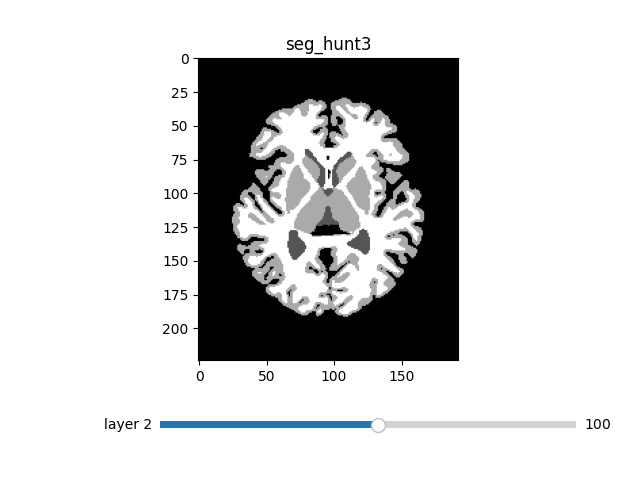

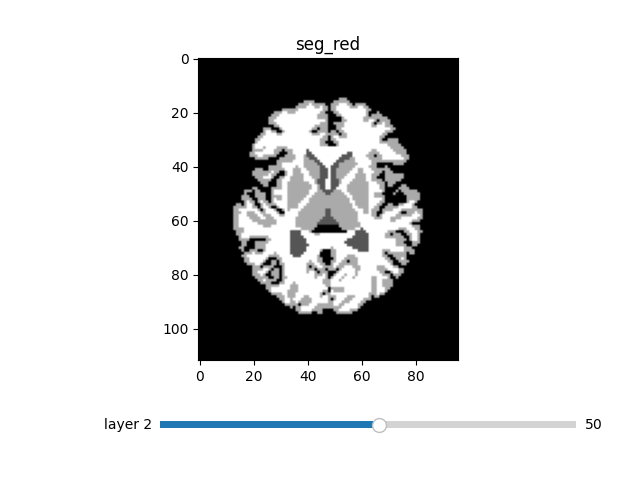

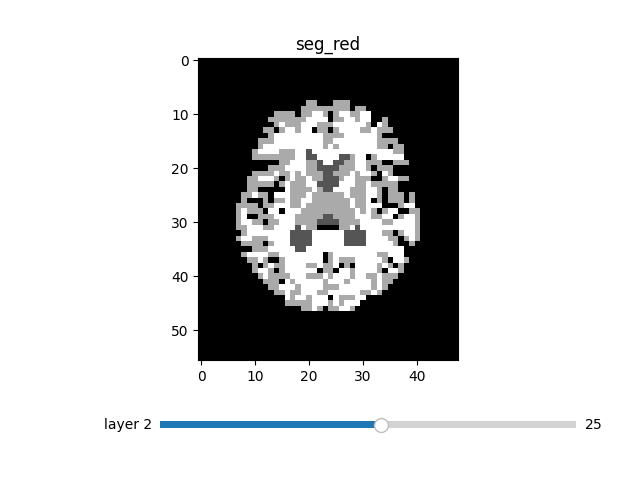

In [12]:




# seg_red = tf.nn.pool(seg_hunt3, window_shape=(2, 2, 2), pooling_type='AVG', strides=(2, 2, 2), padding='VALID')
# seg_red = tf.nn.pool(seg_red, window_shape=(2, 2, 2), pooling_type='AVG', strides=(2, 2, 2), padding='VALID')
# seg_red = tf.cast(tf.round(seg_red), tf.int32)
# seg_red = tf.cast(seg_red, tf.int32)

seg_red_2 = fc.reduce_3D_images_batch(seg_hunt3, scaling_factor=2)
seg_red_1 = fc.reduce_3D_images_batch(seg_red_2, scaling_factor=2)

print(seg_hunt3.shape)
print(seg_red_2.shape)
print(seg_red_1.shape)

print(np.unique(seg_hunt3))
print(np.unique(seg_red_2))
print(np.unique(seg_red_1))


fc.imgshow_3D(f"seg_hunt3", seg_hunt3[0,...,0])
fc.imgshow_3D(f"seg_red", seg_red_2[0,...,0], current_plane=100//2)
fc.imgshow_3D(f"seg_red", seg_red_1[0,...,0], current_plane=100//4)


In [ ]:
def em_sklearn_tf():
    id = matching_ids[1]
    img, mask, seg_3 = load_img_mask_and_segmentation(id, 3, no_cerebellum=False)
    mask_from_seg = np.where(seg_3 > 0, 1, 0)

    img_flat_masked = img.ravel()[mask_from_seg.ravel() > 0]
    labels, means, stds, classs_weights, probs = em_sklearn_tf(img_flat_masked, 3)
    seg_y_ret = recover_labels(labels, mask_from_seg)
    fc.imgshow_3D(f"seg_y_ret", seg_y_ret)




# tensor = tf.constant([2, 2, 2, 1])
# depth = 3

# # Convertir el tensor a one-hot
# one_hot_tensor = tf.one_hot(tensor, depth)

# print("Tensor original:", tensor)
# print("Tensor one-hot:")
# print(one_hot_tensor)